# Piecemaker archive: gaps and unclear data

What the export does not contain, or contains in a form that is hard to read: empty fields, entries without author, videos without notes, days with only one kind of record, implausible values, and notes that mark their own uncertainty. The other notebooks filter most of this out before the analysis. Here it is the subject.

The csv files with the archive export are not part of this repository. The notebook is committed with its outputs, without annotation texts or names.

In [1]:
import re

import pandas as pd
import numpy as np
from plotnine import *

events_df = pd.read_csv("pm1-tfc-2016-events.csv")
pieces_df = pd.read_csv("pm1-tfc-2016-pieces.csv")

for col in ["happened_at", "created_at", "updated_at"]:
    events_df[col] = pd.to_datetime(events_df[col], errors="coerce", format="mixed")

In [2]:
LANG = 'en'   # 'de' or 'en', switches the figure labels

def L(de, en):
    return de if LANG == 'de' else en

PASTEL_RED, PASTEL_BLUE = '#cd867e', '#7ec5cd'
BAR_GREY = '#6b6b6b'

theme_set(
    theme_minimal()
    + theme(plot_title=element_text(size=12),
            plot_subtitle=element_text(size=9),
            legend_title=element_blank())
)

In [3]:
videos = events_df[events_df["event_type"] == "video"].copy()
# text annotations: everything except videos and notes, as in the other notebooks
annotations = events_df[~events_df["event_type"].isin(["video", "note"])].copy()

piece_map = pieces_df.set_index("id")["title"].to_dict()
piece_map[pieces_df.loc[pieces_df["title"] == "Nuo", "id"].iloc[0]] = "Duo/Nuo"
piece_map[pieces_df.loc[pieces_df["title"] == "Duo", "id"].iloc[0]] = "Duo/Nuo"

print(len(videos), "video entries,", len(annotations), "text annotations")

2388 video entries, 6516 text annotations


## Empty fields

Share of entries per year in which a field is empty. Years are those of the entry itself (`happened_at`). Video entries dated before 2008 are left out here, they are older recordings added to the archive later (see below). "Performers" is a list field that could be filled in for each annotation, "location" a free field. Both are never filled for video entries and are not shown for them. A duration counts as empty if it is missing or implausible (see below).

In [4]:
def has_list(s):
    # performers are stored as a yaml list, '--- []' is the empty list
    return s.fillna("").str.contains(r"^---\s*\n-", regex=True)

def filled(s):
    return s.notna() & (s.astype(str).str.strip() != "") & (s.astype(str).str.strip() != "none")

video_ids = set(videos["id"])

ann_fields = pd.DataFrame({
    "year": annotations["happened_at"].dt.year,
    L("Titel", "title"): filled(annotations["title"]),
    L("Beschreibung", "description"): filled(annotations["description"]),
    L("Autor:in", "author"): filled(annotations["created_by"]),
    L("Video-ID", "video id"): annotations["video_id"].isin(video_ids),
    L("Ort", "location"): filled(annotations["location"]),
    L("Beteiligte", "performers"): has_list(annotations["performers"]),
})
ann_fields["kind"] = L("Textannotationen", "text annotations")

dur = pd.to_numeric(videos["dur"], errors="coerce")
vid_fields = pd.DataFrame({
    "year": videos["happened_at"].dt.year,
    L("Dauer (plausibel)", "duration (plausible)"): (dur > 0) & (dur <= 12 * 3600),
    L("Autor:in", "author"): filled(videos["created_by"]),
})
vid_fields["kind"] = L("Videoeinträge", "video entries")

empty_long = []
for df in [ann_fields, vid_fields]:
    df = df[df["year"] >= 2008]
    long = df.melt(id_vars=["year", "kind"], var_name="field", value_name="filled")
    empty_long.append(long.groupby(["kind", "field", "year"])["filled"]
                      .agg(empty=lambda s: 1 - s.mean(), n="size").reset_index())
empty_df = pd.concat(empty_long)
empty_df["year"] = empty_df["year"].astype(int).astype(str)
empty_df["label"] = (empty_df["empty"] * 100).round(0).astype(int).astype(str) + "%"

field_order = [L("Titel", "title"), L("Beschreibung", "description"), L("Autor:in", "author"),
               L("Video-ID", "video id"), L("Dauer (plausibel)", "duration (plausible)"),
               L("Ort", "location"), L("Beteiligte", "performers")]
empty_df["field"] = pd.Categorical(empty_df["field"], categories=field_order[::-1], ordered=True)

empty_df.pivot_table(index=["kind", "field"], columns="year", values="empty", observed=True).round(2)

year                                   2008  2009  2010  2011  2012  2013  \
kind             field                                                      
text annotations performers            0.67  0.59  0.65  0.54  0.60  0.69   
                 location              0.42  0.55  0.60  0.40  0.34  1.00   
                 video id              0.03  0.19  0.11  0.08  0.09  0.50   
                 author                0.39  0.33  0.42  0.38  0.31  0.00   
                 description           0.19  0.14  0.29  0.38  0.56  0.59   
                 title                 0.14  0.13  0.22  0.14  0.11  0.02   
video entries    duration (plausible)  0.01  0.07  0.02  0.00  0.02  0.02   
                 author                1.00  1.00  1.00  1.00  0.70  0.00   

year                                   2014  
kind             field                       
text annotations performers             NaN  
                 location               NaN  
                 video id               NaN  
                 author                 NaN  
                 description            NaN  
                 title                  NaN  
video entries    duration (plausible)  0.04  
                 author                0.00

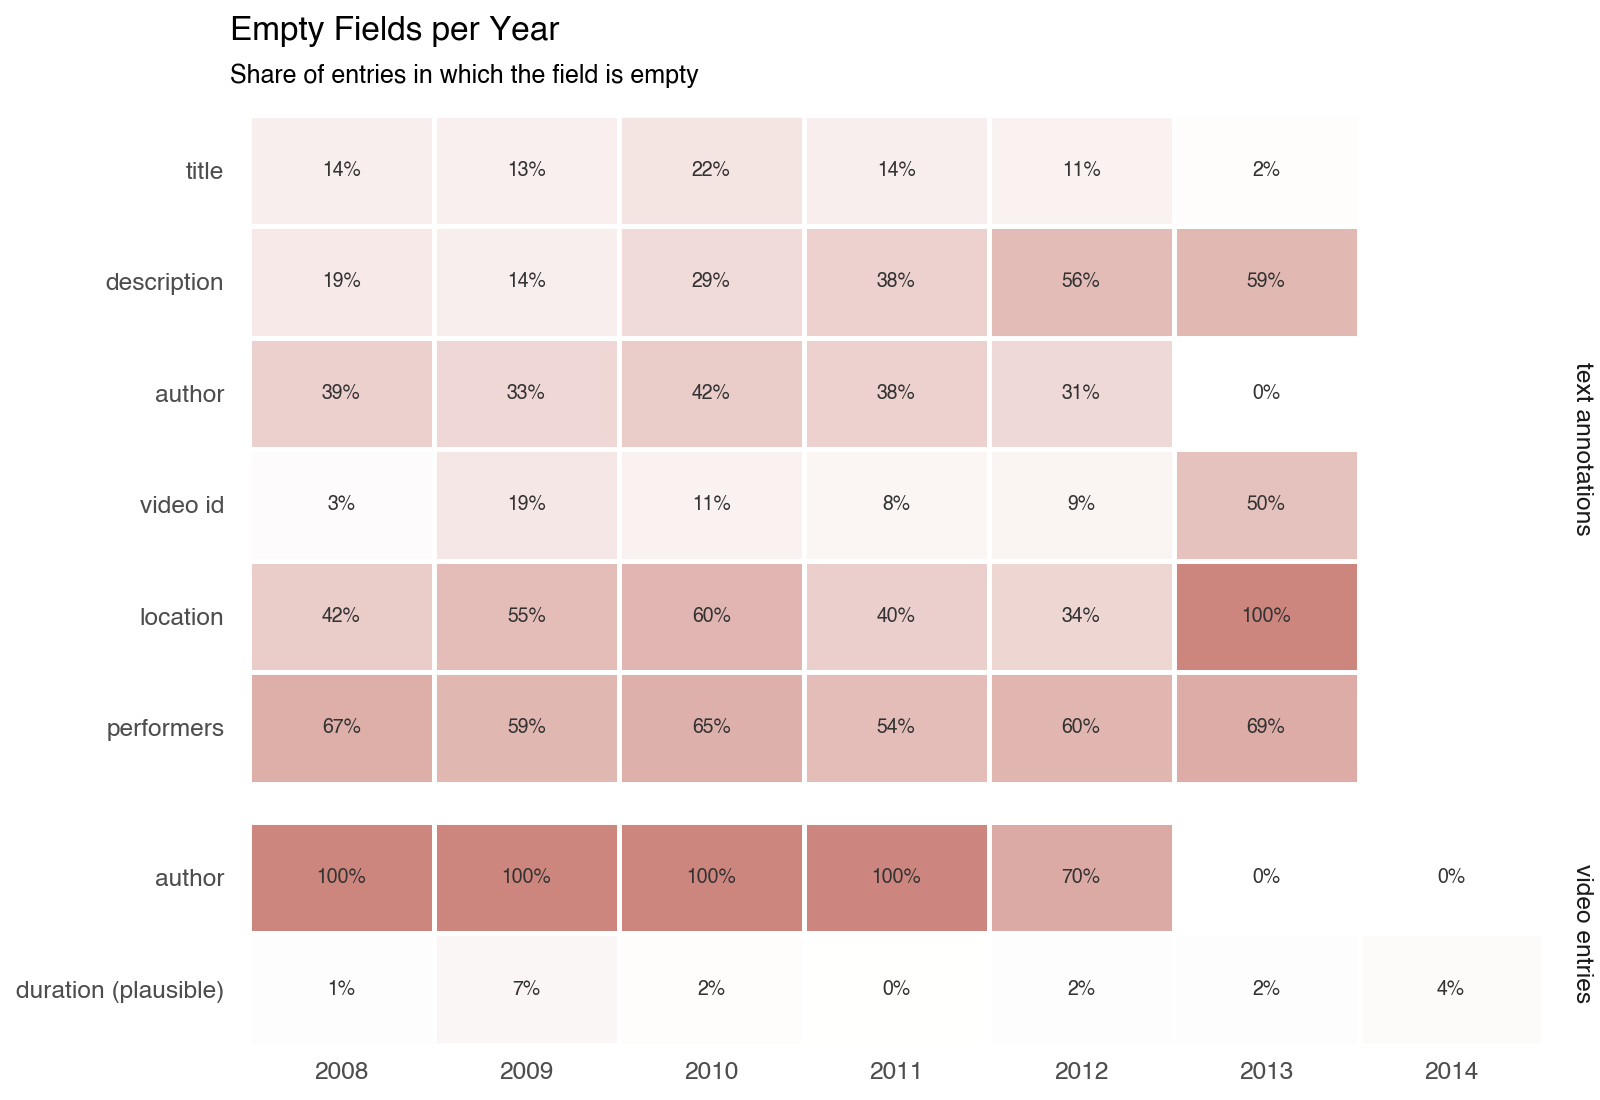

In [5]:
(ggplot(empty_df, aes(x="year", y="field", fill="empty"))
 + geom_tile(color="white", size=1)
 + geom_text(aes(label="label"), size=7, color="#333333")
 + scale_fill_gradient(low="#ffffff", high=PASTEL_RED, limits=(0, 1),
                       labels=lambda v: [f"{x:.0%}" for x in v])
 + facet_grid("kind ~ .", scales="free_y", space="free_y")
 + labs(title=L("Leere Felder pro Jahr", "Empty Fields per Year"),
        subtitle=L("Anteil der Einträge, in denen das Feld leer ist",
                   "Share of entries in which the field is empty"),
        x="", y="")
 + theme(figure_size=(8, 5.5), panel_grid=element_blank(), legend_position="none")
)

In [6]:
both_empty = annotations["title"].isna() & annotations["description"].isna()
print("text annotations with neither title nor description:", int(both_empty.sum()))
print("entries without date (happened_at):",
      events_df[events_df["happened_at"].isna()]["event_type"].value_counts().to_dict())

text annotations with neither title nor description: 115
entries without date (happened_at): {'note': 179, 'scene': 1}


## Entries without author

A third of the text annotations and most video entries have no author in the export. These entries are not spread over the archive. The text annotations among them form one contiguous range of database ids, and all were last modified on the same day.

In [7]:
annotations["no_author"] = annotations["created_by"].isna()
no_auth = annotations[annotations["no_author"]]

print(f"text annotations without author: {len(no_auth)} of {len(annotations)} "
      f"({len(no_auth) / len(annotations):.0%})")
print("database ids:", no_auth["id"].min(), "to", no_auth["id"].max())
in_range = annotations["id"].between(no_auth["id"].min(), no_auth["id"].max())
print("text annotations with author in this id range:", int((in_range & ~annotations["no_author"]).sum()))
print("created between", no_auth["created_at"].min().date(), "and", no_auth["created_at"].max().date())
print("last modified on:", no_auth["updated_at"].dt.date.value_counts().to_dict())

minute = no_auth["created_at"].dt.floor("min")
top_minute = minute.value_counts().index[0]
with_text = no_auth["title"].notna() | no_auth["description"].notna()
print(f"created in the same minute ({top_minute}): {int((minute == top_minute).sum())}, "
      f"{int(((minute == top_minute) & with_text).sum())} of them with text")
print(f"recorded event dates of these: {no_auth.loc[minute == top_minute, 'happened_at'].min().date()} "
      f"to {no_auth.loc[minute == top_minute, 'happened_at'].max().date()}")

text annotations without author: 2142 of 6516 (33%)
database ids: 23228 to 25376
text annotations with author in this id range: 0
created between 2010-09-25 and 2012-04-20
last modified on: {datetime.date(2012, 10, 31): 2142}
created in the same minute (2010-09-25 13:26:00): 964, 954 of them with text
recorded event dates of these: 2008-02-04 to 2010-04-05


When an entry happened (`happened_at`) and when its database record was created (`created_at`) can be compared. Notes typed during rehearsal lie on the diagonal. Horizontal lines are records created in one go for events that happened earlier, as in an import.

In [8]:
def created_vs_happened(df, kind):
    out = df[["happened_at", "created_at", "created_by"]].dropna(subset=["happened_at"]).copy()
    out["author"] = np.where(out["created_by"].isna(), L("ohne Autor:in", "no author"),
                             L("mit Autor:in", "author recorded"))
    out["lag_days"] = (out["created_at"] - out["happened_at"]).dt.total_seconds() / 86400
    out["kind"] = kind
    return out

cvh = pd.concat([created_vs_happened(annotations, L("Textannotationen", "text annotations")),
                 created_vs_happened(videos, L("Videoeinträge", "video entries"))])
cvh = cvh[cvh["happened_at"] >= "2008-01-01"]

for (kind, author), g in cvh.groupby(["kind", "author"]):
    print(f"{kind}, {author}: n = {len(g)}, record created within a day of the event: "
          f"{(g['lag_days'].abs() < 1).mean():.0%}")

text annotations, author recorded: n = 4373, record created within a day of the event: 99%
text annotations, no author: n = 2142, record created within a day of the event: 54%
video entries, author recorded: n = 445, record created within a day of the event: 100%
video entries, no author: n = 1474, record created within a day of the event: 55%


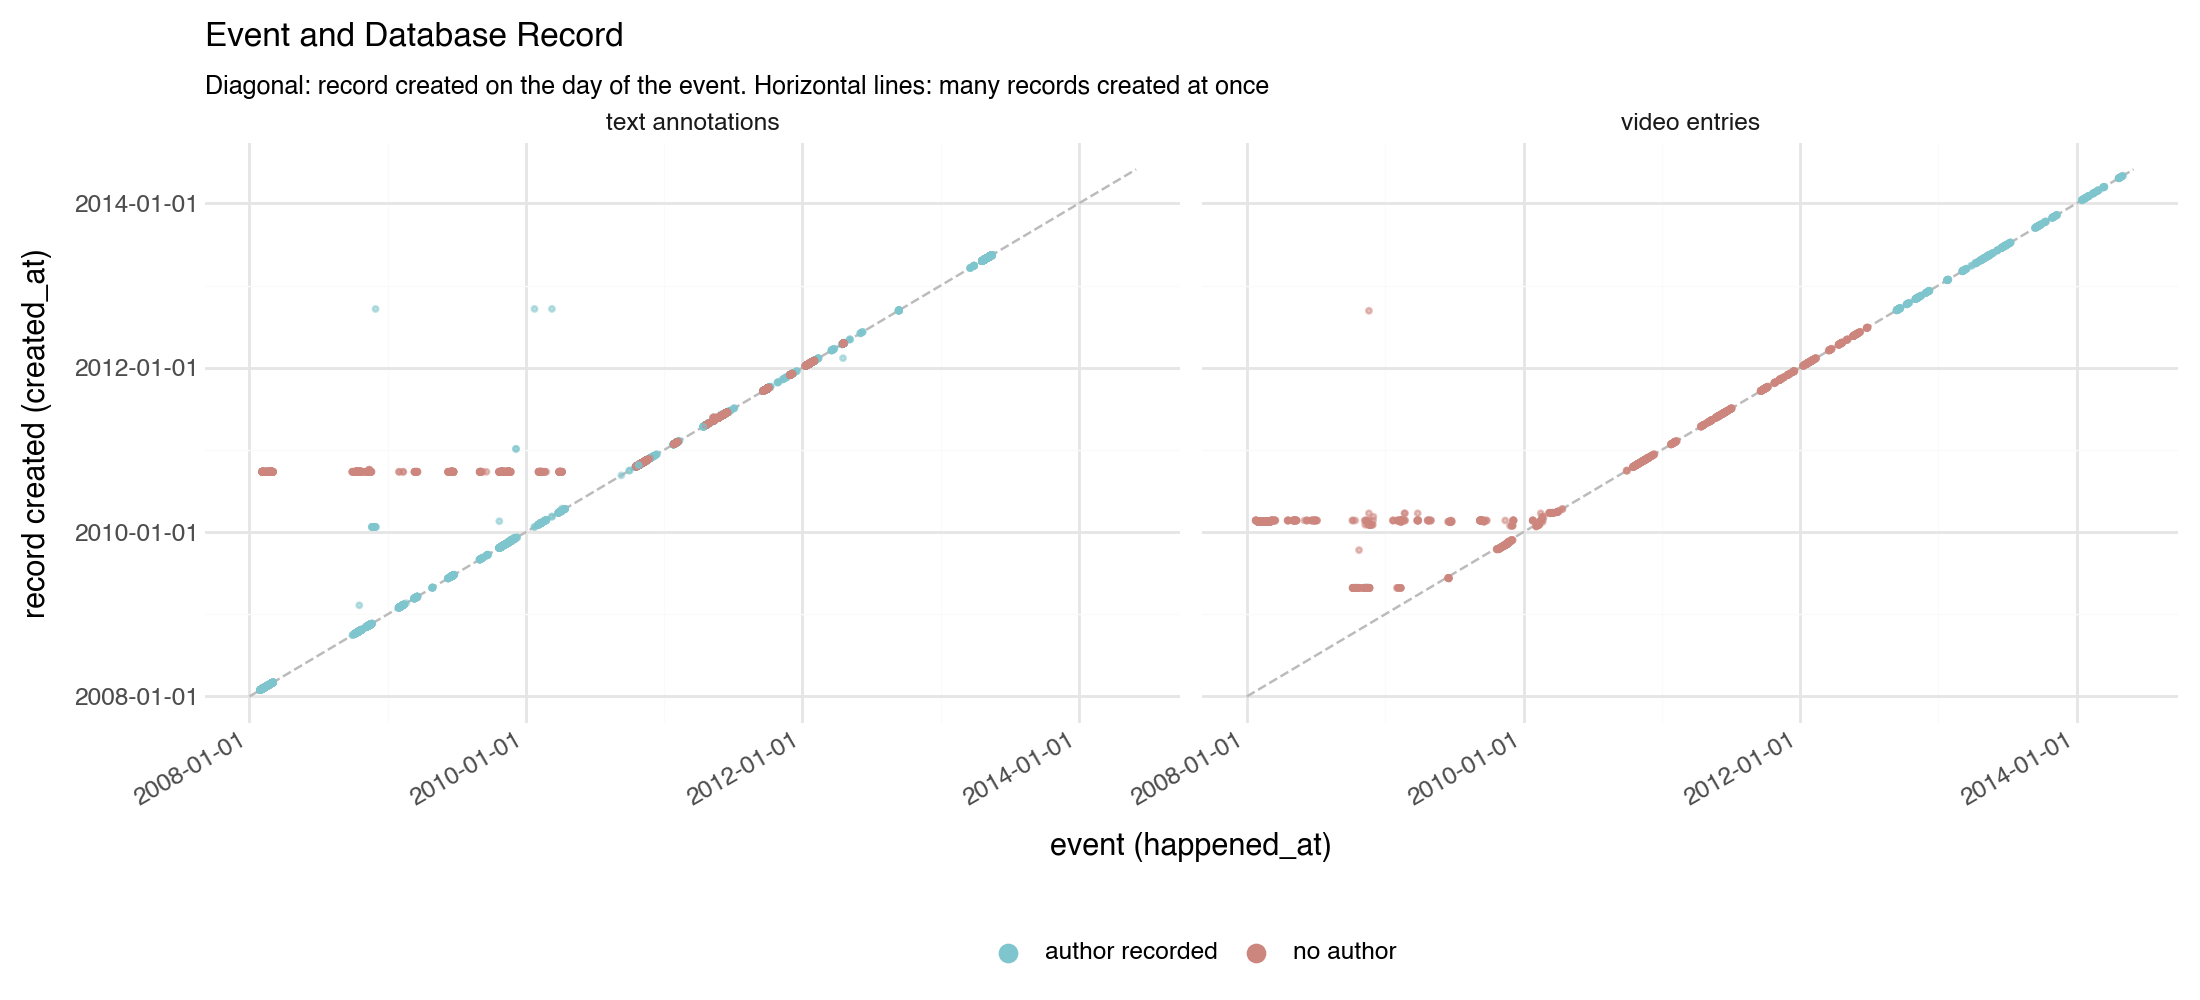

In [9]:
diag = pd.DataFrame({"x": pd.to_datetime(["2008-01-01", "2014-06-01"])})

(ggplot(cvh, aes(x="happened_at", y="created_at", color="author"))
 + geom_line(diag, aes(x="x", y="x"), inherit_aes=False, color="#bbbbbb", linetype="dashed")
 + geom_point(size=0.6, alpha=0.5)
 + scale_color_manual(values=[PASTEL_BLUE, PASTEL_RED])
 + facet_wrap("~kind")
 + labs(title=L("Ereignis und Datenbankeintrag", "Event and Database Record"),
        subtitle=L("Diagonale: Eintrag am Tag des Ereignisses angelegt. Waagerechte Linien: viele Einträge zur selben Zeit angelegt",
                   "Diagonal: record created on the day of the event. Horizontal lines: many records created at once"),
        x=L("Ereignis (happened_at)", "event (happened_at)"),
        y=L("Datenbankeintrag angelegt (created_at)", "record created (created_at)"))
 + guides(color=guide_legend(override_aes={"size": 3, "alpha": 1}))
 + theme(figure_size=(11, 5), legend_position="bottom",
         axis_text_x=element_text(rotation=30, hjust=1))
)

In [10]:
# video records created in bulk
vmin = videos["created_at"].dt.floor("min").value_counts().head(3)
for m, n in vmin.items():
    dated = videos.loc[videos["created_at"].dt.floor("min") == m, "happened_at"]
    print(f"{m}: {n} video entries created, event dates {dated.min().date()} to {dated.max().date()}")

old = videos[videos["happened_at"] < "2008-01-01"]
print(f"\nvideo entries dated before 2008: {len(old)}, record created on",
      old["created_at"].dt.date.value_counts().to_dict())
print("most common last-modified dates of all entries:",
      events_df["updated_at"].dt.date.value_counts().head(3).to_dict())

2010-02-21 07:17:00: 636 video entries created, event dates 1987-04-04 to 2010-02-21
2010-02-16 05:09:00: 159 video entries created, event dates 2008-01-29 to 2009-09-18
2009-04-27 14:21:00: 139 video entries created, event dates 2008-10-06 to 2009-02-10

video entries dated before 2008: 469, record created on {datetime.date(2010, 2, 21): 466, datetime.date(2010, 3, 25): 3}
most common last-modified dates of all entries: {datetime.date(2012, 10, 31): 4137, datetime.date(2012, 9, 10): 3331, datetime.date(2012, 8, 29): 438}


## Videos without notes

Notes are linked to a video by its id. Some later notes have no id but fall within the recording time of a video of the same piece, these are counted as linked as well. Videos from 2008 on with a plausible duration only (0 < duration ≤ 12 h). Notes were mainly written in rehearsals, partly also in revival rehearsals. Performances were as a rule not annotated.

In [11]:
vids = videos.copy()
vids["dur"] = pd.to_numeric(vids["dur"], errors="coerce")
vids = vids[(vids["dur"] > 0) & (vids["dur"] <= 12 * 3600) & (vids["happened_at"] >= "2008-01-01")].copy()
vids["end"] = vids["happened_at"] + pd.to_timedelta(vids["dur"], unit="s")

notes_by_id = annotations.groupby("video_id").size()
vids["notes_by_id"] = vids["id"].map(notes_by_id).fillna(0).astype(int)

# notes without video id: inside the recording time of a video of the same piece?
unlinked = annotations[annotations["video_id"].isna()].dropna(subset=["happened_at"])
by_time = []
for _, v in vids.iterrows():
    inside = (unlinked["piece_id"] == v["piece_id"]) & unlinked["happened_at"].between(v["happened_at"], v["end"])
    by_time.append(int(inside.sum()))
vids["notes_by_time"] = by_time
vids["notes"] = vids["notes_by_id"] + vids["notes_by_time"]
vids["hours"] = vids["dur"] / 3600
vids["year"] = vids["happened_at"].dt.year

total_h = vids["hours"].sum()
silent_h = vids.loc[vids["notes"] == 0, "hours"].sum()
print(f"videos: {len(vids)}, {total_h:.0f} hours")
print(f"videos without any note: {(vids['notes'] == 0).sum()} ({(vids['notes'] == 0).mean():.0%}), "
      f"{silent_h:.0f} hours ({silent_h / total_h:.0%} of the video time)")
print("of the notes counted, linked by time only:", int(vids["notes_by_time"].sum()))

videos: 1876, 1740 hours
videos without any note: 821 (44%), 719 hours (41% of the video time)
of the notes counted, linked by time only: 395


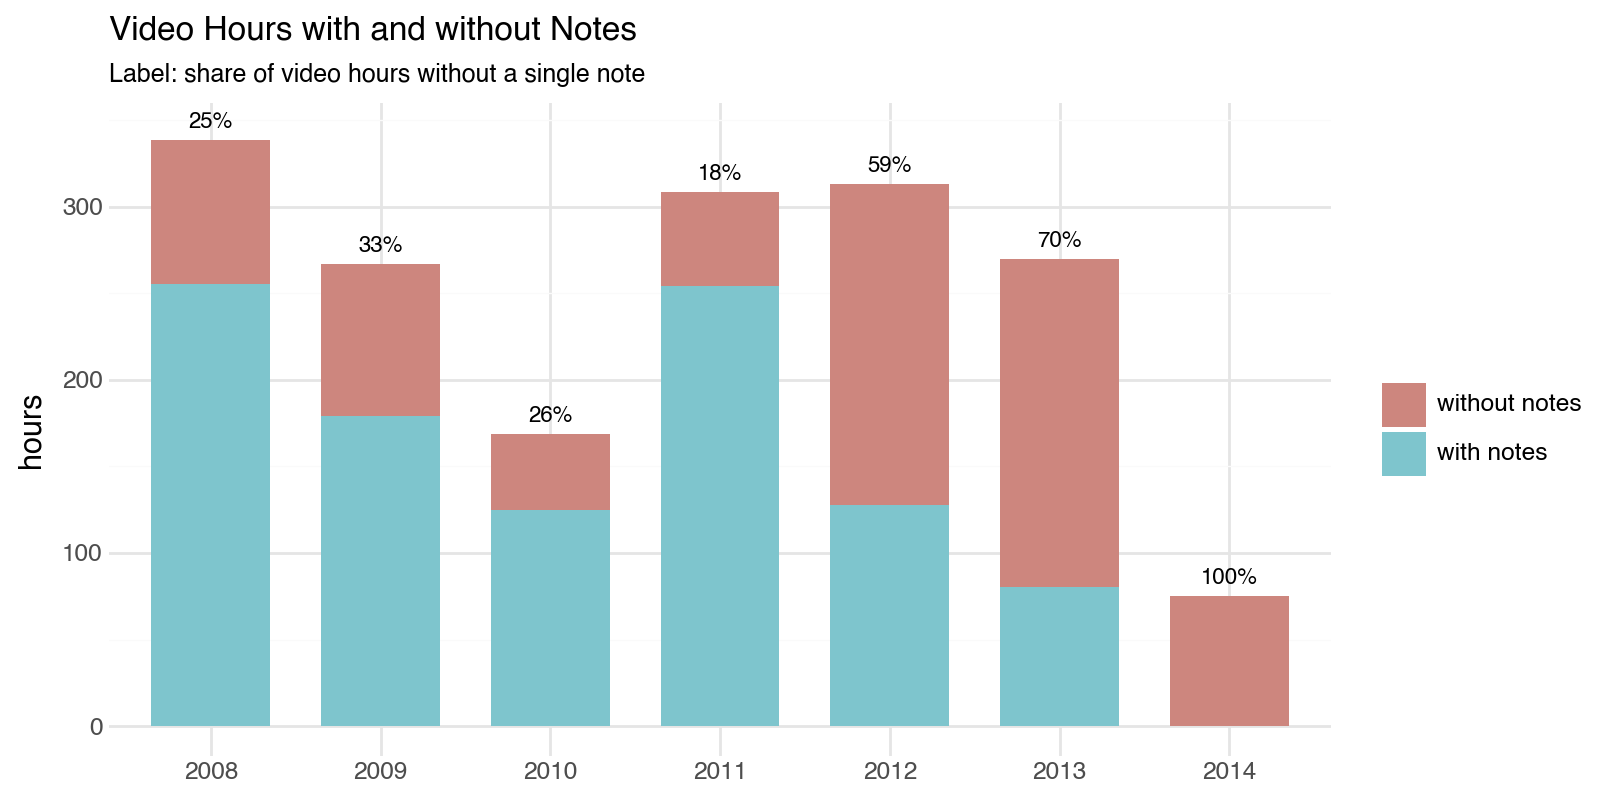

In [12]:
per_year = (vids.assign(with_notes=vids["notes"] > 0)
            .groupby(["year", "with_notes"])["hours"].sum().reset_index())
per_year["status"] = np.where(per_year["with_notes"], L("mit Notizen", "with notes"),
                              L("ohne Notizen", "without notes"))
per_year["status"] = pd.Categorical(per_year["status"],
                                    categories=[L("ohne Notizen", "without notes"), L("mit Notizen", "with notes")])
per_year["year"] = per_year["year"].astype(str)

share = (per_year[~per_year["with_notes"]].set_index("year")["hours"]
         / per_year.groupby("year")["hours"].sum()).fillna(0)
labels = pd.DataFrame({"year": share.index,
                       "total": per_year.groupby("year")["hours"].sum().loc[share.index].values,
                       "label": [f"{s:.0%}" for s in share.values]})

(ggplot(per_year, aes(x="year", y="hours", fill="status"))
 + geom_col(width=0.7)
 + geom_text(labels, aes(x="year", y="total", label="label"), inherit_aes=False,
             va="bottom", size=8, nudge_y=4)
 + scale_fill_manual(values=[PASTEL_RED, PASTEL_BLUE])
 + labs(title=L("Videostunden mit und ohne Notizen", "Video Hours with and without Notes"),
        subtitle=L("Beschriftung: Anteil der Videostunden ohne eine einzige Notiz",
                   "Label: share of video hours without a single note"),
        x="", y=L("Stunden", "hours"))
 + theme(figure_size=(8, 4))
)

In [13]:
# active pieces with >= 150 annotations, as in the overview table of pm1_archive_analytics
ann_counts = annotations.groupby("piece_id").size()
active_ids = set(pieces_df.loc[pieces_df["is_active"] == True, "id"])
main_pieces = [p for p in ann_counts[ann_counts >= 150].index if p in active_ids]

piece_rows = []
for pid in main_pieces:
    g = vids[vids["piece_id"] == pid]
    if g.empty:
        continue
    piece_rows.append({
        "piece": piece_map[pid],
        "video hours": round(g["hours"].sum()),
        "hours without notes": round(g.loc[g["notes"] == 0, "hours"].sum()),
        "share without notes": round(g.loc[g["notes"] == 0, "hours"].sum() / g["hours"].sum(), 2),
        "notes per video hour": round(g["notes"].sum() / g["hours"].sum(), 1),
        "from": g["happened_at"].min().year,
    })
pd.DataFrame(piece_rows).sort_values("from").reset_index(drop=True)

,piece,video hours,hours without notes,share without notes,notes per video hour,from
0,Yes We Can't,286,102,0.36,3.0,2008
1,I Don't Believe in Outer Space,189,56,0.30,3.3,2008
2,The Returns,116,59,0.50,1.3,2009
3,Theatrical Arsenal 2*,139,4,0.03,5.4,2009
4,Whole in the Head,120,26,0.22,5.6,2010
5,Sider,230,98,0.43,3.8,2011
6,STELLENTSTELLEN,100,26,0.26,5.3,2011
7,Now This When Not That,66,5,0.08,6.8,2011
8,Hellerau,93,17,0.18,7.3,2013


Within videos that do have notes, the notes are not evenly spread. For each such video: the longest stretch of recording time without a note (from the start, between two notes, or up to the end).

In [14]:
offsets = annotations[annotations["video_id"].isin(vids["id"])][["video_id", "happened_at"]].copy()
offsets["offset"] = (offsets["happened_at"]
                     - offsets["video_id"].map(vids.set_index("id")["happened_at"])).dt.total_seconds()
offsets = offsets[(offsets["offset"] >= 0)
                  & (offsets["offset"] <= offsets["video_id"].map(vids.set_index("id")["dur"]))]

longest = []
for vid, g in offsets.groupby("video_id"):
    d = vids.loc[vids["id"] == vid, "dur"].iloc[0]
    points = np.concatenate([[0], np.sort(g["offset"].values), [d]])
    longest.append(np.diff(points).max() / 60)
longest = pd.Series(longest)

print(f"videos with notes inside the recording time: {len(longest)}")
print(f"longest stretch without a note, median {longest.median():.0f} min "
      f"(IQR {longest.quantile(0.25):.0f}-{longest.quantile(0.75):.0f} min), "
      f"over an hour in {(longest > 60).mean():.0%} of the videos")

videos with notes inside the recording time: 1037
longest stretch without a note, median 20 min (IQR 12-36 min), over an hour in 13% of the videos


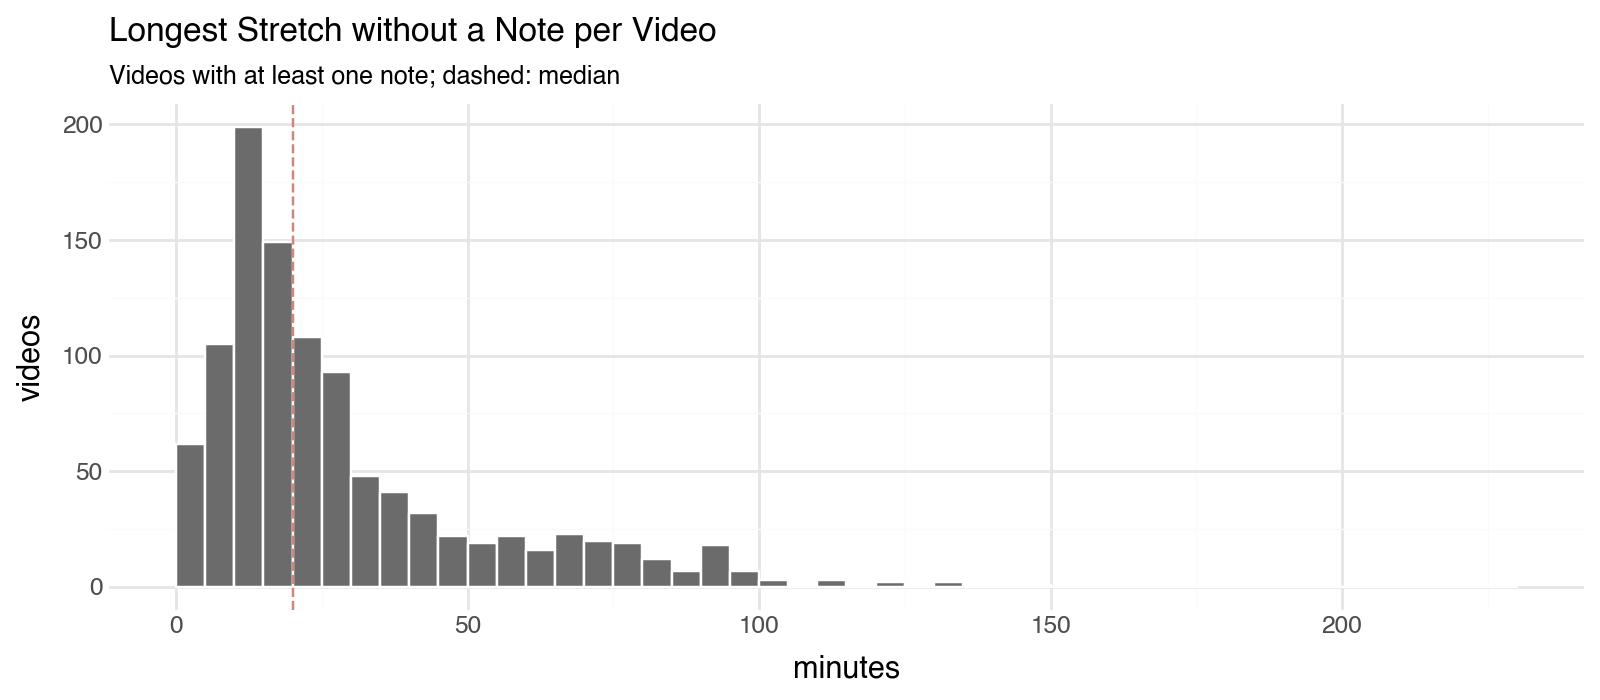

In [15]:
(ggplot(pd.DataFrame({"minutes": longest}), aes(x="minutes"))
 + geom_histogram(binwidth=5, boundary=0, fill=BAR_GREY, color="white")
 + geom_vline(xintercept=longest.median(), linetype="dashed", color=PASTEL_RED)
 + labs(title=L("Längster Abschnitt ohne Notiz je Video", "Longest Stretch without a Note per Video"),
        subtitle=L("Videos mit mindestens einer Notiz; gestrichelt: Median",
                   "Videos with at least one note; dashed: median"),
        x=L("Minuten", "minutes"), y=L("Videos", "videos"))
 + theme(figure_size=(8, 3.5))
)

## Recording days

Per production: calendar days with video and notes, with video only, with notes only. White space between the marks is time without any record for that production.

In [16]:
days = events_df[events_df["piece_id"].isin(main_pieces) & (events_df["happened_at"] >= "2008-01-01")].copy()
days["day"] = days["happened_at"].dt.normalize()
days["is_video"] = days["event_type"] == "video"
days["is_note"] = ~days["event_type"].isin(["video", "note"])

day_types = days.groupby(["piece_id", "day"]).agg(video=("is_video", "any"), notes=("is_note", "any")).reset_index()
day_types["type"] = np.select(
    [day_types["video"] & day_types["notes"], day_types["video"]],
    [L("Video und Notizen", "video and notes"), L("nur Video", "video only")],
    default=L("nur Notizen", "notes only"))
day_types["piece"] = day_types["piece_id"].map(piece_map)

first_day = day_types.groupby("piece")["day"].min().sort_values(ascending=False)
day_types["piece"] = pd.Categorical(day_types["piece"], categories=first_day.index, ordered=True)
day_types["type"] = pd.Categorical(day_types["type"], categories=[
    L("Video und Notizen", "video and notes"), L("nur Video", "video only"), L("nur Notizen", "notes only")])

(day_types.groupby(["piece", "type"], observed=False).size().unstack()
 .assign(total=lambda d: d.sum(axis=1)).iloc[::-1])

type,video and notes,video only,notes only,total
piece,,,,
Yes We Can't,59,35,5,99
I Don't Believe in Outer Space,52,20,13,85
The Returns,20,24,3,47
Theatrical Arsenal 2*,42,1,2,45
Whole in the Head,45,12,1,58
Sider,49,36,1,86
Now This When Not That,18,0,1,19
STELLENTSTELLEN,30,9,2,41
Hellerau,23,8,2,33


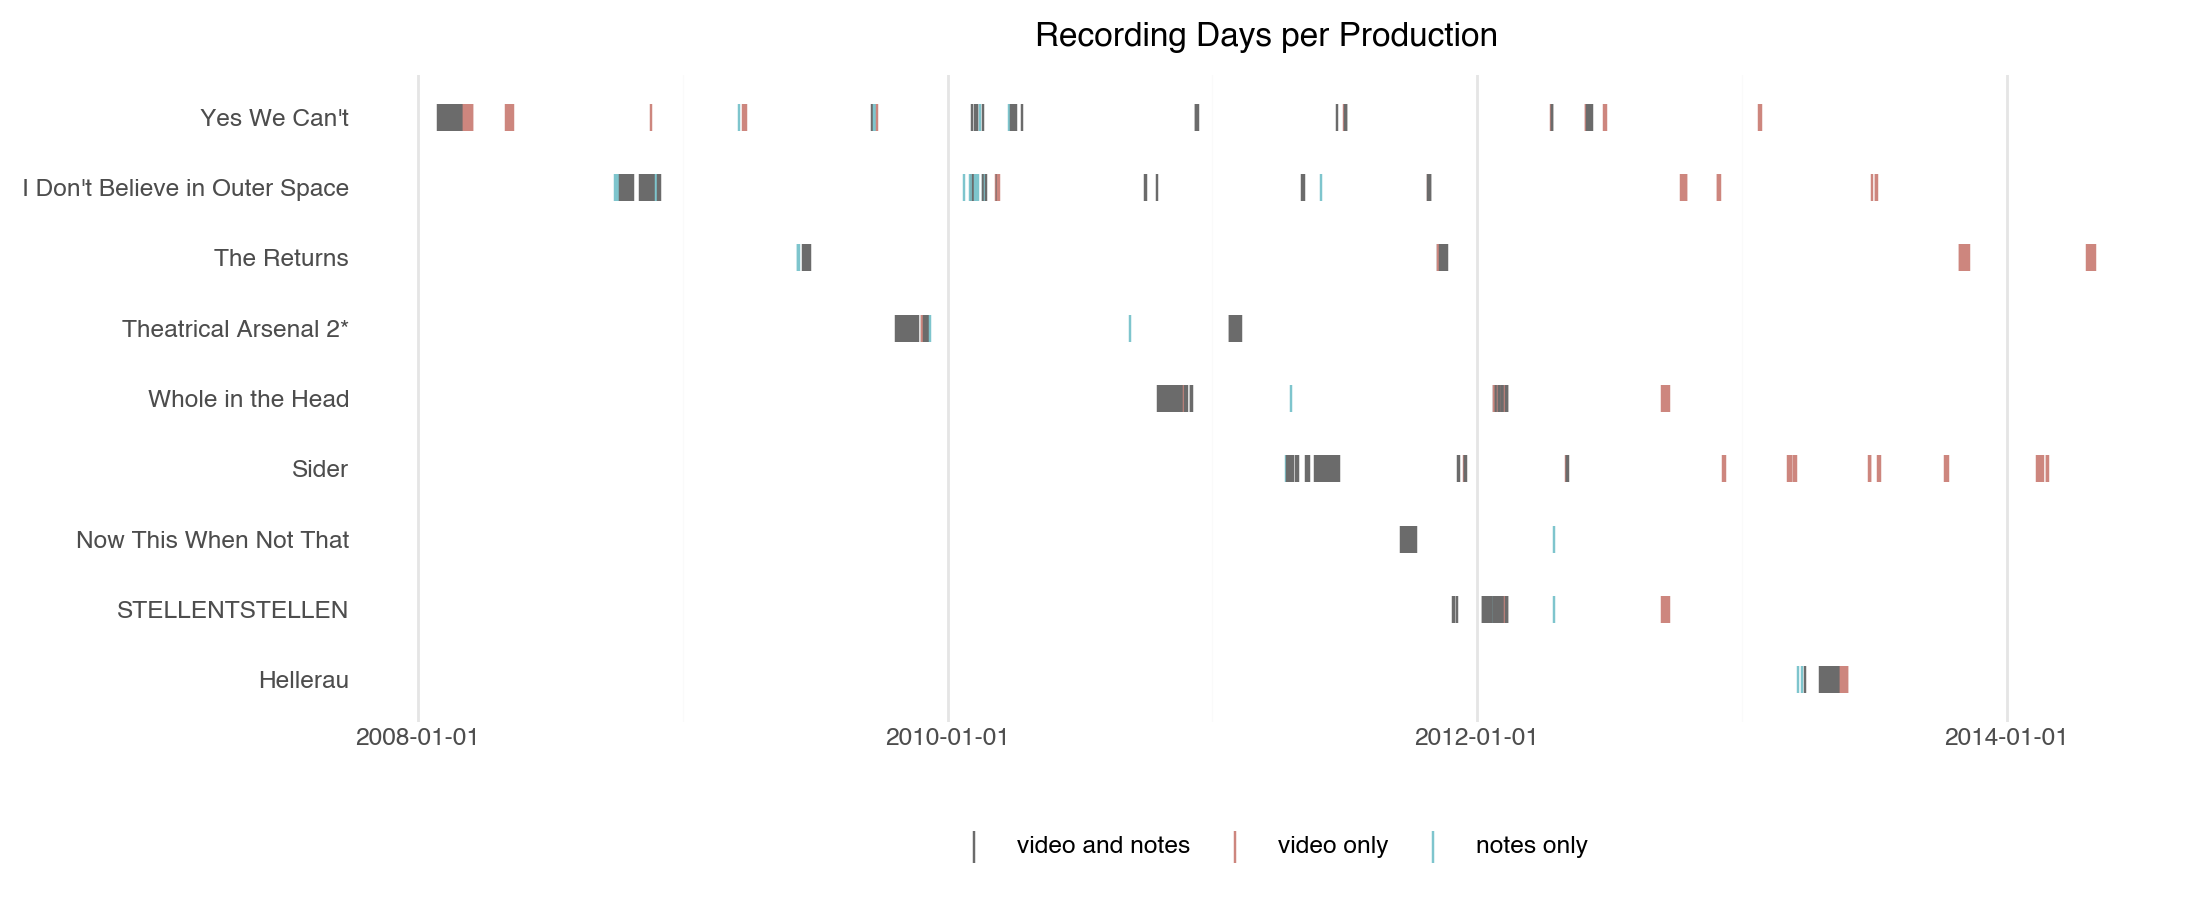

In [17]:
(ggplot(day_types, aes(x="day", y="piece", color="type"))
 + geom_point(shape="|", size=5)
 + scale_color_manual(values=[BAR_GREY, PASTEL_RED, PASTEL_BLUE])
 + labs(title=L("Aufzeichnungstage je Produktion", "Recording Days per Production"),
        x="", y="")
 + guides(color=guide_legend(override_aes={"size": 6}))
 + theme(figure_size=(11, 4.5), legend_position="bottom", panel_grid_major_y=element_blank())
)

In [18]:
# breaks in the documentation of a production, as for the time series (GAP_DAYS = 3)
GAP_DAYS = 3
break_rows = []
for piece in first_day.index[::-1]:
    g = day_types[day_types["piece"] == piece]
    diffs = g["day"].sort_values().diff().dt.days.dropna()
    break_rows.append({"piece": piece, "recording days": len(g),
                       "first": g["day"].min().date(), "last": g["day"].max().date(),
                       f"breaks > {GAP_DAYS} days": int((diffs > GAP_DAYS).sum()),
                       "longest break (days)": int(diffs.max())})
pd.DataFrame(break_rows)

,piece,recording days,first,last,breaks > 3 days,longest break (days)
0,Yes We Can't,99,2008-01-29,2013-01-27,18,282
1,I Don't Believe in Outer Space,85,2008-09-29,2013-07-06,14,419
2,The Returns,47,2009-06-08,2014-05-03,4,866
3,Theatrical Arsenal 2*,45,2009-10-22,2011-02-10,3,275
4,Whole in the Head,58,2010-10-18,2012-09-22,4,279
5,Sider,86,2011-04-13,2014-02-27,13,214
6,Now This When Not That,19,2011-09-19,2012-04-17,1,191
7,STELLENTSTELLEN,41,2011-11-29,2012-09-22,4,149
8,Hellerau,33,2013-03-19,2013-05-26,3,21


## Implausible and contradictory values

Values that cannot be right as they stand, or that contradict each other. Most of them are excluded silently in the other notebooks.

In [19]:
dur_all = pd.to_numeric(videos["dur"], errors="coerce")

linked = annotations[annotations["video_id"].isin(vids["id"])].copy()
v_idx = vids.set_index("id")
outside = ~linked["happened_at"].between(linked["video_id"].map(v_idx["happened_at"]),
                                         linked["video_id"].map(v_idx["end"]))
missing_target = annotations["video_id"].notna() & ~annotations["video_id"].isin(video_ids)

texts = annotations["title"].fillna("") + " " + annotations["description"].fillna("")

issues = pd.DataFrame([
    ("video entries without duration", int(dur_all.isna().sum())),
    ("video entries with duration <= 0", int((dur_all <= 0).sum())),
    (f"video entries with duration > 12 h (max {dur_all.max() / 3600:.0f} h)", int((dur_all > 12 * 3600).sum())),
    ("video entries dated before 2008 (before Piecemaker)", int((videos["happened_at"] < "2008-01-01").sum())),
    ("entries without date", int(events_df["happened_at"].isna().sum())),
    ("text annotations linked to a video missing from the export", int(missing_target.sum())),
    ("  ... number of these missing videos", int(annotations.loc[missing_target, "video_id"].nunique())),
    ("text annotations outside the recording time of their video", int(outside.sum())),
    ("entries marked as deleted", int((events_df["state"] == "deleted").sum())),
    ("entries marked as draft of another entry", int(events_df["state"].str.startswith("draft_of").sum())),
    ("pieces with two database entries (Duo / Nuo)", 1),
    ("text annotations with broken character encoding", int(texts.str.contains("Ã|â€|Â").sum())),
    ("text annotations with HTML markup in the text", int(texts.str.contains(r"<\s*br|<[a-z]+[ >]|&nbsp;", case=False).sum())),
], columns=["issue", "entries"])
issues

,issue,entries
0,video entries without duration,203
1,video entries with duration <= 0,7
2,video entries with duration > 12 h (max 94 h),22
3,video entries dated before 2008 (before Piecem...,469
4,entries without date,180
5,text annotations linked to a video missing fro...,100
6,... number of these missing videos,53
7,text annotations outside the recording time of...,72
8,entries marked as deleted,68
9,entries marked as draft of another entry,67


In [20]:
# the event times of the entries without author are as reliable as the others
linked["no_author"] = linked["created_by"].isna()
inside_share = (~outside).groupby(linked["no_author"]).mean()
print(f"text annotations inside the recording time of their video: "
      f"with author {inside_share[False]:.1%}, without author {inside_share[True]:.1%}")

text annotations inside the recording time of their video: with author 98.8%, without author 98.5%


## Notes that mark their own uncertainty

Some notes say themselves that something is unclear, with a question mark in brackets (after a name, a piece of music, a cue) or a double question mark. The pattern below is simple and also catches a few quoted questions. Very short notes are listed as well: many are a name or a scene title and only make sense together with the video.

In [21]:
text_df = annotations[annotations["title"].notna() | annotations["description"].notna()].copy()
text_df["text"] = (text_df["title"].fillna("") + " " + text_df["description"].fillna("")).str.strip()

doubt = re.compile(r"\([^()]{0,80}\?[^()]{0,40}\)|\?\?")
text_df["doubt"] = text_df["text"].str.contains(doubt)
text_df["words"] = text_df["text"].str.split().str.len()
text_df["year"] = text_df["happened_at"].dt.year

print(f"notes with a marked doubt: {text_df['doubt'].sum()} of {len(text_df)} ({text_df['doubt'].mean():.1%})")
print(f"notes with at most three words: {(text_df['words'] <= 3).sum()} ({(text_df['words'] <= 3).mean():.0%})")

(text_df.groupby("year")
 .agg(notes=("text", "size"), marked_doubt=("doubt", "sum"),
      at_most_3_words=("words", lambda s: round((s <= 3).mean(), 2)))
 .reset_index().astype({"year": int}))

notes with a marked doubt: 115 of 6401 (1.8%)
notes with at most three words: 918 (14%)


,year,notes,marked_doubt,at_most_3_words
0,2008,1386,35,0.11
1,2009,1081,29,0.05
2,2010,909,17,0.16
3,2011,1593,21,0.18
4,2012,702,6,0.24
5,2013,729,7,0.15


## Figures and tables for the dissertation

German labels and print size, written to `figures/`. In the dissertation the text annotations are called "Annotationen". The video hours are in greyscale, the recording days keep the three colours.

In [22]:
from pathlib import Path

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
GREY_DARK, GREY_MID, GREY_LIGHT = '#333333', '#7f7f7f', '#c9c9c9'   # as in pm1_archive_analytics (COLOR_MODE 'grey')
PRINT_SIZE  = (5.8, 2.9)
PRINT_THEME = theme(text=element_text(size=8), plot_title=element_text(size=9),
                    plot_subtitle=element_text(size=7.5), axis_title=element_text(size=8),
                    axis_text=element_text(size=7.5), legend_text=element_text(size=7.5),
                    legend_title=element_blank())

# video hours with and without annotations per year
py = per_year.copy()
py['status'] = np.where(py['with_notes'], 'mit Annotationen', 'ohne Annotationen')
py['status'] = pd.Categorical(py['status'], categories=['ohne Annotationen', 'mit Annotationen'])
p_hours = (ggplot(py, aes(x='year', y='hours', fill='status'))
 + geom_col(width=0.7)
 + geom_text(labels.assign(label=labels['label'].str.replace('%', ' %')),
             aes(x='year', y='total', label='label'), inherit_aes=False, va='bottom', size=7, nudge_y=4)
 + scale_fill_manual(values=[GREY_LIGHT, GREY_DARK])
 + labs(title='Videostunden mit und ohne Annotationen',
        subtitle='Beschriftung: Anteil der Videostunden ohne eine einzige Annotation',
        x='', y='Stunden')
 + PRINT_THEME + theme(figure_size=PRINT_SIZE))
p_hours.save(FIG_DIR / 'archive_video_hours_annotations_per_year_de.png', dpi=300, verbose=False)

# recording days per production, colours as in the figure above
dt = day_types.copy()
de_types = {'video and notes': 'Video und Annotationen', 'video only': 'nur Video', 'notes only': 'nur Annotationen',
            'Video und Notizen': 'Video und Annotationen', 'nur Notizen': 'nur Annotationen'}
dt['type'] = pd.Categorical(dt['type'].astype(str).replace(de_types),
                            categories=['Video und Annotationen', 'nur Video', 'nur Annotationen'])
# two periods stacked, so that single days stay distinguishable at text width; no title (the caption carries it)
dt['period'] = pd.Categorical(np.where(dt['day'] < pd.Timestamp('2011-01-01'), '2008–2010', '2011–2014'),
                              categories=['2008–2010', '2011–2014'])
span = pd.DataFrame({'day': pd.to_datetime(['2008-01-01', '2010-12-31', '2011-01-01', '2014-06-30']),
                     'piece': [dt['piece'].iloc[0]] * 4,
                     'period': pd.Categorical(['2008–2010', '2008–2010', '2011–2014', '2011–2014'],
                                              categories=['2008–2010', '2011–2014'])})
p_days = (ggplot(dt, aes(x='day', y='piece', color='type'))
 + geom_blank(span, aes(x='day', y='piece'), inherit_aes=False)
 + geom_point(shape='|', size=3.2, stroke=0.35)
 + facet_wrap('period', ncol=1, scales='free_x')
 + scale_color_manual(values=[BAR_GREY, PASTEL_RED, PASTEL_BLUE])
 + scale_x_datetime(date_breaks='6 months', date_labels='%Y-%m', expand=(0.01, 0))
 + labs(x='', y='')
 + guides(color=guide_legend(override_aes={'size': 5, 'stroke': 0.8}))
 + PRINT_THEME
 + theme(figure_size=(5.8, 5.6), legend_position='bottom',
         strip_text=element_text(size=8, ha='left', margin={'t': 4, 'b': 3}), strip_background=element_blank(),
         panel_spacing_y=0.045,
         panel_grid_major_y=element_blank(), panel_grid_minor=element_blank()))
p_days.save(FIG_DIR / 'archive_recording_days_per_production_de.png', dpi=300, verbose=False)

# tables: video hours without annotations per production, kinds of recording days
pd.DataFrame(piece_rows).sort_values('from').to_csv(FIG_DIR / 'archive_video_hours_annotations_per_piece.csv', index=False)
(day_types.groupby(['piece', 'type'], observed=False).size().unstack()
 .assign(total=lambda d: d.sum(axis=1)).iloc[::-1].to_csv(FIG_DIR / 'archive_recording_day_types_per_piece.csv'))
per_year.pivot(index='year', columns='with_notes', values='hours').fillna(0).round(1).rename(
    columns={True: 'hours_with_annotations', False: 'hours_without_annotations'}
).to_csv(FIG_DIR / 'archive_video_hours_annotations_per_year.csv')
print('saved to', FIG_DIR)

saved to figures
